# 04 · Gráficos descriptivos de la presentación

**Proyecto:** Salud mental en el sector tecnológico · De una encuesta larga a 7 preguntas
**Autor:** Hugo Nascimento · Proyecto final Data Analytics · IT Academy (Barcelona Activa)

En este notebook calculo y dibujo los gráficos **descriptivos** de la presentación (la participación en la encuesta y el bloque del EDA), directamente desde la base de datos SQLite que creé en el notebook 01. Los gráficos del Random Forest están al final del notebook 03.

Todos los números salen de la base de datos: no hay ningún valor escrito a mano. Guardo cada gráfico en `04_figuras` con el prefijo `p_`.

**Un color = un significado:** verde = hablaría o respuesta favorable, coral = callaría o respuesta desfavorable, frambuesa = tener un trastorno, gris = el resto.

### Solo si ejecutas el notebook en Google Colab
La primera celda conecta con Google Drive. Fuera de Colab no hace nada.

In [1]:
import os, sys                                          # os: carpetas; sys: saber dónde se ejecuta
if "google.colab" in sys.modules:                       # si estoy en Google Colab...
    from google.colab import drive                      # ...importo la conexión con Drive
    drive.mount("/content/drive")                       # monto mi Google Drive
    os.chdir("/content/drive/MyDrive/SPRINT13_PROYECTO_FINAL_HUGO_NASCIMENTO/02_notebooks")   # me sitúo en la carpeta de notebooks

## 0. Librerías, colores y datos

In [2]:
import sqlite3                                          # para leer la base de datos SQLite
from pathlib import Path                                # para escribir rutas de archivos
import numpy as np                                      # cálculo numérico
import pandas as pd                                     # tablas
import matplotlib.pyplot as plt                         # gráficos
from matplotlib.patches import Rectangle                # cuadrados del gráfico de waffle

BASE = Path.cwd().parent                                # carpeta principal del proyecto
RUTA_SQLITE = BASE / "01_datos" / "procesados" / "salud_mental_tech.db"
RUTA_FIGURAS = BASE / "04_figuras"
RUTA_FIGURAS.mkdir(exist_ok=True)

VERDE, CORAL, FRAMBUESA, PIZARRA = "#2E7D72", "#D9634C", "#A23B72", "#3B4252"   # un color = un significado
GRIS, GRIS2, TINTA, TINTA2 = "#CEC8BC", "#E7E1D6", "#15171C", "#5C6270"
plt.rcParams.update({"font.family": ["Inter", "DejaVu Sans"], "font.size": 18,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRIS})

def guardar(fig, nombre):
    fig.savefig(RUTA_FIGURAS / nombre, dpi=150, bbox_inches="tight", facecolor="white")   # lo guardo en 04_figuras
    print("Guardado: 04_figuras/" + nombre)

def pct(x):
    return f"{x:.0f} %"                                 # 42.3 → "42 %"

In [3]:
# Personas (con su año) y todas sus respuestas
with sqlite3.connect(RUTA_SQLITE) as con:
    personas = pd.read_sql("""SELECT pe.persona_id, e.anio, pe.autonomo
                              FROM personas pe JOIN encuestas e ON e.encuesta_id = pe.encuesta_id""", con)
    respuestas = pd.read_sql("SELECT persona_id, pregunta_id, respuesta FROM respuestas", con)
respuestas = respuestas.merge(personas, on="persona_id")                     # cada respuesta con su año

# Tabla ancha: una fila por persona y una columna por pregunta (si hay varias respuestas, la primera)
ancha = respuestas.pivot_table(index="persona_id", columns="pregunta_id", values="respuesta", aggfunc="first")
ancha = ancha.join(personas.set_index("persona_id"))

# Los empleados por cuenta ajena de 2017 a 2019: los mismos datos del Random Forest
empleados = ancha[(ancha["anio"] >= 2017) & (ancha["autonomo"] == 0)]
con_trastorno = empleados[empleados[33] == "Sí"]                            # los que dicen tener un trastorno ahora
print("Empleados 2017-2019:", len(empleados), "· con un trastorno ahora:", len(con_trastorno))

Empleados 2017-2019: 1308 · con un trastorno ahora: 573


## 1. Cada año más preguntas y menos gente

Cuento, para cada año de la encuesta, cuántas personas contestaron, cuántas preguntas había y qué % de respuestas quedaron en blanco.

Guardado: 04_figuras/p_participacion.png
De 1433 personas en 2016 a 352 en 2019: −75%


,personas,preguntas,% en blanco
anio,,,
2014,1260,26,6.0
2016,1433,60,23.0
2017,756,76,30.0
2018,417,76,29.0
2019,352,76,30.0


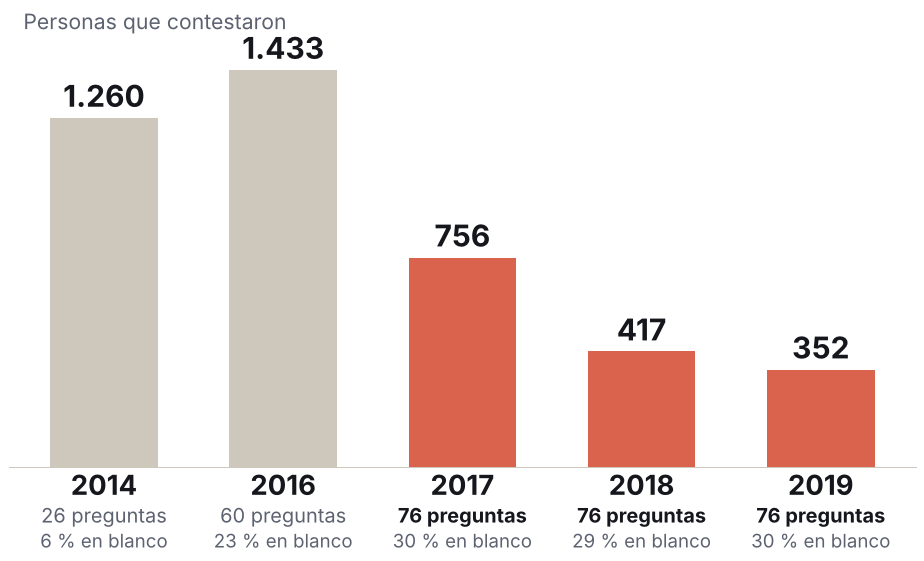

In [4]:
participacion = pd.DataFrame({
    "personas": personas.groupby("anio")["persona_id"].nunique(),                       # personas que contestaron
    "preguntas": respuestas.groupby("anio")["pregunta_id"].nunique(),                   # preguntas de ese año
    "% en blanco": respuestas.groupby("anio")["respuesta"].apply(lambda s: s.isna().mean() * 100).round(0)})
display(participacion)

fig, ax = plt.subplots(figsize=(13, 6.6))
anios = [str(a) for a in participacion.index]
colores = [CORAL if q == participacion["preguntas"].max() else GRIS for q in participacion["preguntas"]]   # en coral, los años de 76 preguntas
ax.bar(anios, participacion["personas"], width=0.6, color=colores)
for i, (anio, fila) in enumerate(participacion.iterrows()):
    larga = fila["preguntas"] == participacion["preguntas"].max()
    ax.text(i, fila["personas"] + 40, f"{fila['personas']:,.0f}".replace(",", "."), ha="center", fontsize=24, fontweight="bold", color=TINTA)
    ax.text(i, -100, str(anio), ha="center", fontsize=22, fontweight="bold", color=TINTA)
    ax.text(i, -200, f"{fila['preguntas']:.0f} preguntas", ha="center", fontsize=16, color=(TINTA if larga else TINTA2), fontweight=("bold" if larga else "normal"))
    ax.text(i, -290, f"{fila['% en blanco']:.0f} % en blanco", ha="center", fontsize=15, color=TINTA2)
ax.set_ylim(0, 1650); ax.set_yticks([]); ax.set_xticks([]); ax.spines["left"].set_visible(False)
ax.text(-0.45, 1580, "Personas que contestaron", fontsize=17, color=TINTA2)
guardar(fig, "p_participacion.png")
plt.show()
caida = 1 - participacion.loc[2019, "personas"] / participacion.loc[2016, "personas"]
print(f"De {participacion.loc[2016, 'personas']} personas en 2016 a {participacion.loc[2019, 'personas']} en 2019: −{caida:.0%}")

**Lectura:** cuando la encuesta pasa a 76 preguntas, la participación cae casi a la mitad y sigue bajando, y crecen las respuestas en blanco. Es una **señal, no una prueba de causa**: también pudo influir que la encuesta perdiera novedad o difusión, y parte de los blancos son preguntas que no tocaban (por ejemplo, las de la empresa anterior a quien no la tuvo).

## 2. Hallazgo 1 · ¿Es un problema frecuente?

Pregunta 33 (¿tienes ahora un trastorno de salud mental?), de 2016 a 2019 (en 2014 no se preguntó así).

2958 personas · Sí 42 % · no lo tienen claro 25 % · No 33 %
Guardado: 04_figuras/p_waffle_trastorno.png


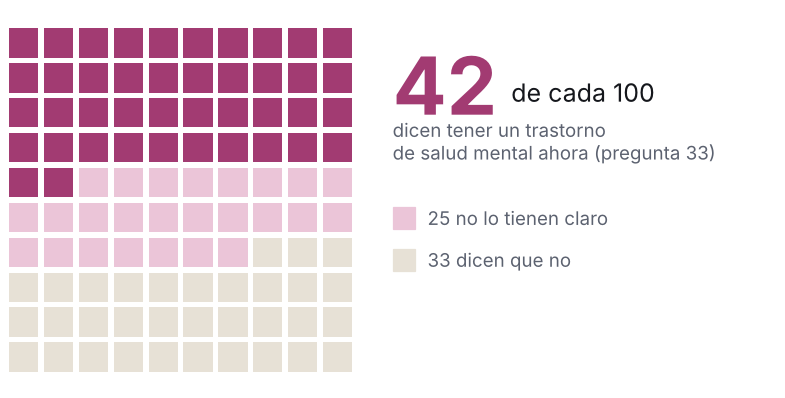

In [5]:
p33 = ancha.loc[ancha["anio"] >= 2016, 33].dropna()                         # respuestas válidas de 2016 a 2019
reparto = p33.value_counts(normalize=True) * 100
si = round(reparto.get("Sí", 0))
no = round(reparto.get("No", 0))
dudan = 100 - si - no                                                        # Quizá, Posiblemente y No lo sé
print(f"{len(p33)} personas · Sí {si} % · no lo tienen claro {dudan} % · No {no} %")

fig, ax = plt.subplots(figsize=(11, 6.2)); ax.set_xlim(0, 22); ax.set_ylim(-0.5, 10.4); ax.axis("off"); ax.set_aspect("equal")
colores = [FRAMBUESA] * si + ["#EBC5D8"] * dudan + [GRIS2] * no
for k, c in enumerate(colores):                                              # 100 cuadrados, de 10 en 10
    ax.add_patch(Rectangle((k % 10, 9 - k // 10), 0.84, 0.84, color=c, lw=0))
ax.text(11, 8.2, str(si), fontsize=64, fontweight="bold", color=FRAMBUESA, va="center")
ax.text(14.4, 8.0, "de cada 100", fontsize=20, color=TINTA, va="center")
ax.text(11, 6.6, "dicen tener un trastorno\nde salud mental ahora (pregunta 33)", fontsize=15, color=TINTA2, va="center")
for y, c, t in [(4.4, "#EBC5D8", f"{dudan} no lo tienen claro"), (3.2, GRIS2, f"{no} dicen que no")]:
    ax.add_patch(Rectangle((11, y - 0.32), 0.64, 0.64, color=c)); ax.text(12, y, t, fontsize=15, color=TINTA2, va="center")
guardar(fig, "p_waffle_trastorno.png")
plt.show()

## 3. Hallazgo 2 · ¿Le afecta al trabajo? Sin y con tratamiento

Entre los empleados de 2017-2019 con un trastorno: con qué frecuencia interfiere en su trabajo **sin tratamiento** (pregunta 49) y **con tratamiento** (pregunta 48). Quito «No aplica».

Guardado: 04_figuras/p_tratamiento.png


,Nunca,Rara vez,A veces,A menudo
Sin tratamiento,0.0,3.0,21.0,76.0
Con tratamiento,4.0,38.0,46.0,11.0


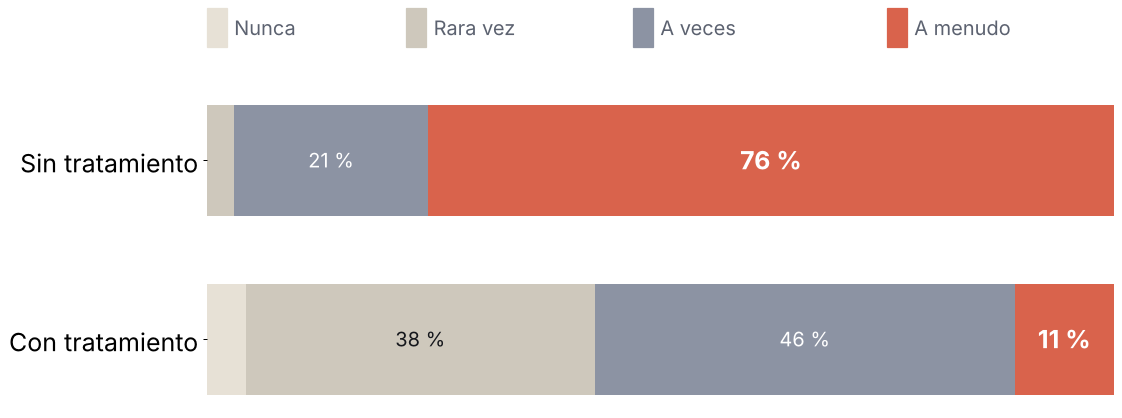

In [6]:
CATS = ["Nunca", "Rara vez", "A veces", "A menudo"]
COLS = [GRIS2, GRIS, "#8C93A3", CORAL]
interferencia = pd.DataFrame({etiqueta: con_trastorno.loc[con_trastorno[q] != "No aplica", q].value_counts(normalize=True) * 100
                              for q, etiqueta in [(49, "Sin tratamiento"), (48, "Con tratamiento")]}).T.reindex(columns=CATS).fillna(0)
display(interferencia.round(0))

fig, ax = plt.subplots(figsize=(13, 4.6))
for i, (etiqueta, fila) in enumerate(interferencia.iterrows()):
    izquierda = 0
    for c, col in zip(CATS, COLS):
        v = fila[c]
        ax.barh(i, v, left=izquierda, color=col, height=0.62)
        if v >= 6:
            ax.text(izquierda + v / 2, i, pct(v), ha="center", va="center", fontsize=(20 if c == "A menudo" else 16),
                    fontweight=("bold" if c == "A menudo" else "normal"), color=("white" if c in ("A menudo", "A veces") else TINTA))
        izquierda += v
ax.set_yticks([0, 1]); ax.set_yticklabels(list(interferencia.index), fontsize=20); ax.invert_yaxis()
ax.set_xlim(0, 100); ax.set_xticks([]); [s.set_visible(False) for s in ax.spines.values()]
for c, col, x in zip(CATS, COLS, [0, 22, 47, 75]):
    ax.add_patch(plt.Rectangle((x, -0.85), 2.2, 0.22, color=col, clip_on=False)); ax.text(x + 3, -0.74, c, va="center", fontsize=16, color=TINTA2)
guardar(fig, "p_tratamiento.png")
plt.show()

## 4. Hallazgo 3 · ¿Se habla en la empresa?

De los empleados de 2017-2019 con un trastorno, cuántos lo han contado alguna vez en su empresa (pregunta 58).

1308 empleados → 573 con un trastorno → 277 lo han contado y 296 no (52%)
Guardado: 04_figuras/p_embudo.png


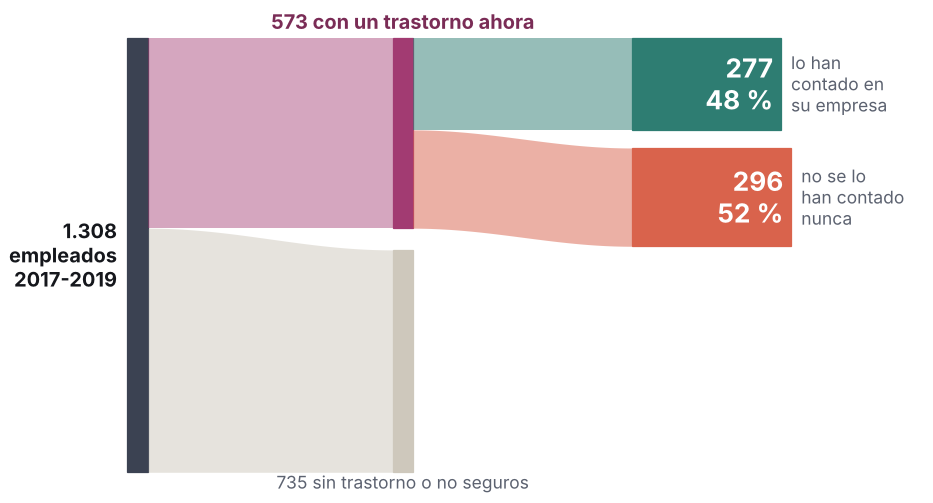

In [7]:
contado = con_trastorno[58].astype(str).map({"1": "Sí", "0": "No", "Sí": "Sí", "No": "No"})   # 1/0 → Sí/No
n_total, n_trastorno = len(empleados), len(con_trastorno)
n_si, n_no = (contado == "Sí").sum(), (contado == "No").sum()
print(f"{n_total} empleados → {n_trastorno} con un trastorno → {n_si} lo han contado y {n_no} no ({n_no / n_trastorno:.0%})")

fig, ax = plt.subplots(figsize=(12, 7)); ax.set_xlim(0, 12.6); ax.set_ylim(0, 13.4); ax.axis("off")
def flujo(x0, y0a, y0b, x1, y1a, y1b, color, alfa=0.55):                    # una banda curva entre dos barras
    t = np.linspace(0, 1, 50); s = (1 - np.cos(np.pi * t)) / 2; xs = x0 + (x1 - x0) * t
    ax.fill_between(xs, y0b + (y1b - y0b) * s, y0a + (y1a - y0a) * s, color=color, alpha=alfa, lw=0)
H = 12.0; escala = H / n_total; y0 = 0.6; arriba = y0 + H
h_t, h_sin = n_trastorno * escala, (n_total - n_trastorno) * escala
ax.add_patch(Rectangle((0.6, y0), 0.32, H, color=PIZARRA))
ax.text(0.45, y0 + H / 2, f"{n_total:,}\nempleados\n2017-2019".replace(",", "."), ha="right", va="center", fontsize=16, color=TINTA, fontweight="bold")
flujo(0.92, arriba, arriba - h_t, 4.6, arriba, arriba - h_t, FRAMBUESA, 0.45); ax.add_patch(Rectangle((4.6, arriba - h_t), 0.3, h_t, color=FRAMBUESA))
ax.text(4.75, arriba + 0.25, f"{n_trastorno} con un trastorno ahora", ha="center", fontsize=16, color="#7A2C56", fontweight="bold")
flujo(0.92, arriba - h_t, y0, 4.6, arriba - h_t - 0.6, y0, GRIS, 0.5); ax.add_patch(Rectangle((4.6, y0), 0.3, h_sin - 0.6, color=GRIS))
ax.text(4.75, y0 - 0.45, f"{n_total - n_trastorno} sin trastorno o no seguros", ha="center", fontsize=14, color=TINTA2)
h_si, h_no, W = n_si * escala, n_no * escala, 2.4                            # el largo de cada barra final es proporcional
flujo(4.9, arriba, arriba - h_si, 8.2, arriba, arriba - h_si, VERDE, 0.5)
ax.add_patch(Rectangle((8.2, arriba - h_si), W * n_si / max(n_si, n_no), h_si, color=VERDE))
flujo(4.9, arriba - h_si, arriba - h_t, 8.2, arriba - h_si - 0.5, arriba - h_t - 0.5, CORAL, 0.5)
ax.add_patch(Rectangle((8.2, arriba - h_t - 0.5), W * n_no / max(n_si, n_no), h_no, color=CORAL))
for n, h, y_c, texto in [(n_si, h_si, arriba - h_si / 2, "lo han\ncontado en\nsu empresa"),
                         (n_no, h_no, arriba - h_si - 0.5 - h_no / 2, "no se lo\nhan contado\nnunca")]:
    largo = W * n / max(n_si, n_no)
    ax.text(8.2 + largo - 0.12, y_c, f"{n}\n{n / n_trastorno:.0%}".replace("%", " %"), fontsize=21, fontweight="bold", color="white", va="center", ha="right")
    ax.text(8.2 + largo + 0.15, y_c, texto, fontsize=14, color=TINTA2, va="center")
guardar(fig, "p_embudo.png")
plt.show()

## 5. Las empresas cuidan más el cuerpo que la mente, y el sector suspende

- Importancia que da la empresa a la salud física (pregunta 64) y a la mental (65), de 0 a 10.
- Nota al sector tech en apoyo a la salud mental (pregunta 85), de 1 a 5. Esta pregunta la responde todo el mundo, así que uso a todas las personas de 2017-2019 (1.523), también a los autónomos.

Física 6.3 · mental 5.0 · nota media al sector 2.55 · 1 o 2: 47 %
Guardado: 04_figuras/p_empresas.png


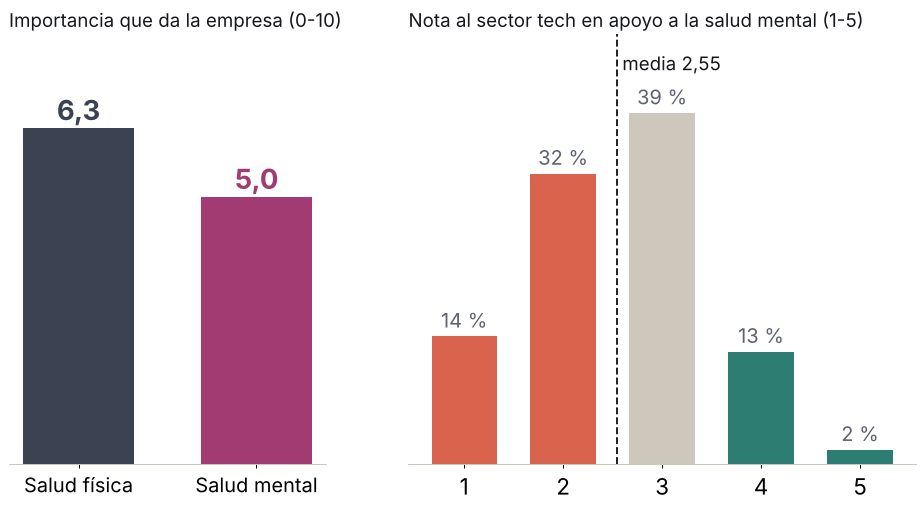

In [8]:
fisica = pd.to_numeric(empleados[64], errors="coerce").mean()               # media de 0 a 10
mental = pd.to_numeric(empleados[65], errors="coerce").mean()
nota = pd.to_numeric(ancha.loc[ancha["anio"] >= 2017, 85], errors="coerce").dropna()   # la 85 la responde todo el mundo (también autónomos)
reparto_nota = nota.value_counts(normalize=True).sort_index() * 100
print(f"Física {fisica:.1f} · mental {mental:.1f} · nota media al sector {nota.mean():.2f} · 1 o 2: {reparto_nota.loc[[1, 2]].sum():.0f} %")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6.2), gridspec_kw={"width_ratios": [1, 1.6]})
a1.bar([0, 1], [fisica, mental], color=[PIZARRA, FRAMBUESA], width=0.62)
for x, v, c in [(0, fisica, PIZARRA), (1, mental, FRAMBUESA)]:
    a1.text(x, v + 0.15, f"{v:.1f}".replace(".", ","), ha="center", fontsize=22, fontweight="bold", color=c)
a1.set_xticks([0, 1]); a1.set_xticklabels(["Salud física", "Salud mental"], fontsize=16); a1.set_ylim(0, 8); a1.set_yticks([]); a1.spines["left"].set_visible(False)
a1.set_title("Importancia que da la empresa (0-10)", fontsize=15, loc="left", color=TINTA)
colores = [CORAL, CORAL, GRIS, VERDE, VERDE]                                 # suspenso en coral, aprobado en verde
a2.bar(reparto_nota.index, reparto_nota.values, color=colores, width=0.66)
for x, v in reparto_nota.items(): a2.text(x, v + 1, pct(v), ha="center", fontsize=16, color=TINTA2)
a2.axvline(nota.mean(), color=TINTA, ls="--", lw=1.5); a2.text(nota.mean() + 0.05, 44, f"media {nota.mean():.2f}".replace(".", ","), fontsize=15, color=TINTA)
a2.set_xticks(range(1, 6)); a2.set_ylim(0, 48); a2.set_yticks([]); a2.spines["left"].set_visible(False)
a2.set_title("Nota al sector tech en apoyo a la salud mental (1-5)", fontsize=15, loc="left", color=TINTA)
guardar(fig, "p_empresas.png")
plt.show()

## 6. Hallazgo 4 · ¿Basta con hablar?

Tres comparaciones entre los empleados de 2017-2019 con un trastorno:

1. ¿Quien se siente cómodo con su supervisor (19) lo ha contado de verdad en su empresa (58)?
2. ¿A quien lo ha contado (58) le afecta menos en el trabajo (49, «a menudo»)?
3. ¿Le afecta menos con tratamiento (48) que sin tratamiento (49)?

¿Quién se siente cómodo, lo cuenta? → no se siente cómodo 22 % · se siente cómodo 76 %
¿Contarlo reduce el impacto? → no lo contó 74 % · lo contó 78 %
¿Tratarse reduce el impacto? → sin tratamiento 76 % · con tratamiento 11 %
Guardado: 04_figuras/p_basta_con_hablar.png


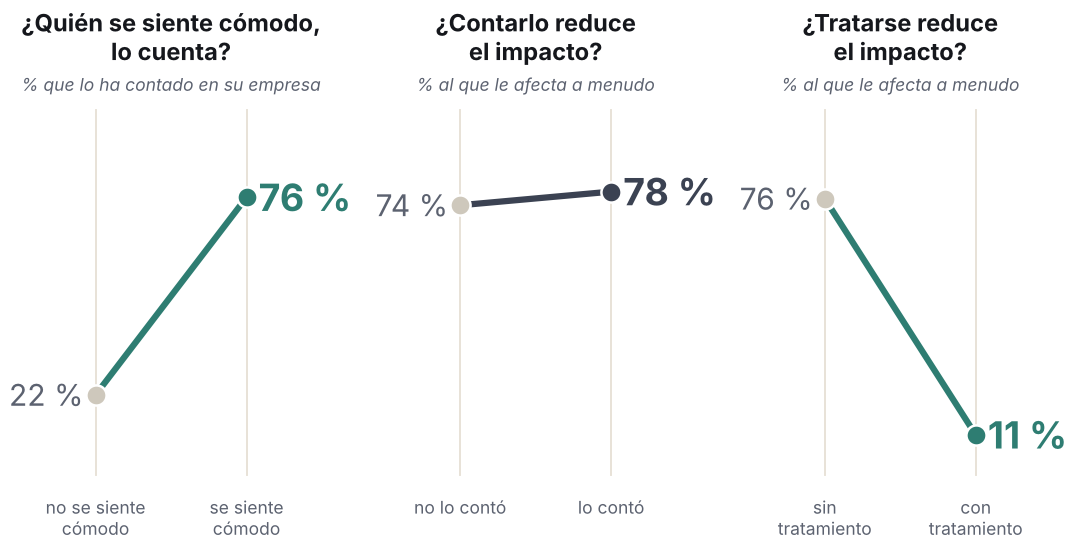

In [9]:
def porcentaje(serie, valor):
    serie = serie[serie.notna() & (serie != "No aplica")]
    return (serie.astype(str) == valor).mean() * 100

contado_txt = con_trastorno[58].astype(str)
comparaciones = [
    ("¿Quién se siente cómodo,\nlo cuenta?", "% que lo ha contado en su empresa", "no se siente\ncómodo", "se siente\ncómodo",
     porcentaje(con_trastorno.loc[con_trastorno[19] == "No", 58], "1"), porcentaje(con_trastorno.loc[con_trastorno[19] == "Sí", 58], "1"), VERDE),
    ("¿Contarlo reduce\nel impacto?", "% al que le afecta a menudo", "no lo contó", "lo contó",
     porcentaje(con_trastorno.loc[contado_txt == "0", 49], "A menudo"), porcentaje(con_trastorno.loc[contado_txt == "1", 49], "A menudo"), PIZARRA),
    ("¿Tratarse reduce\nel impacto?", "% al que le afecta a menudo", "sin\ntratamiento", "con\ntratamiento",
     porcentaje(con_trastorno[49], "A menudo"), porcentaje(con_trastorno[48], "A menudo"), VERDE)]
for t, _, a, b, va, vb, _ in comparaciones: print(t.replace("\n", " "), "→", a.replace("\n", " "), pct(va), "·", b.replace("\n", " "), pct(vb))

fig, ejes = plt.subplots(1, 3, figsize=(15, 7.2), sharey=True)
for ax, (titulo, sub, a, b, va, vb, color) in zip(ejes, comparaciones):
    ax.plot([0, 1], [va, vb], color=color, lw=5, solid_capstyle="round")
    ax.scatter([0], [va], s=260, color=GRIS, zorder=3, edgecolor="white", lw=2); ax.scatter([1], [vb], s=260, color=color, zorder=3, edgecolor="white", lw=2)
    ax.text(-0.08, va, pct(va), ha="right", va="center", fontsize=24, color=TINTA2)
    ax.text(1.08, vb, pct(vb), ha="left", va="center", fontsize=30, fontweight="bold", color=color)
    ax.set_xlim(-0.55, 1.55); ax.set_ylim(-14, 112); ax.axis("off")
    ax.text(0.5, 112, titulo, ha="center", va="bottom", fontsize=19, fontweight="bold", color=TINTA)
    ax.text(0.5, 104, sub, ha="center", va="bottom", fontsize=14, color=TINTA2, style="italic")
    ax.text(0, -6, a, ha="center", va="top", fontsize=14, color=TINTA2); ax.text(1, -6, b, ha="center", va="top", fontsize=14, color=TINTA2)
    ax.plot([0, 0], [0, 100], color=GRIS2, lw=1.5, zorder=0); ax.plot([1, 1], [0, 100], color=GRIS2, lw=1.5, zorder=0)
fig.subplots_adjust(wspace=0.15, top=0.83, bottom=0.12)
guardar(fig, "p_basta_con_hablar.png")
plt.show()

**Lectura:** sentirse cómodo sí va unido a contarlo, pero contarlo por sí solo no reduce el impacto en el trabajo. Lo que lo reduce es **tratarse**. Por eso, además de abrir la puerta, la empresa tiene que facilitar el acceso al tratamiento.

## 7. Hallazgo 6 · ¿Qué puede cambiar la empresa? (radar)

Para cada pregunta del núcleo cojo a **todas** las personas que dan una respuesta favorable y a todas las que dan una desfavorable, y miro qué % de cada grupo hablaría con su supervisor. Son los 875 empleados de 2017-2019 que responden «Sí» o «No» a la 19 (los mismos del modelo 19). No es una muestra de 100 personas: es el porcentaje dentro de cada grupo.

Guardado: 04_figuras/p_radar_clima.png


,favorable,desfavorable
Hablar de salud mental,86,42
Compañeros (81),82,19
Pedir una baja (17),83,17
Importancia que da,81,32
Anonimato protegido (11),75,35
Apoyo del sector (85),76,42


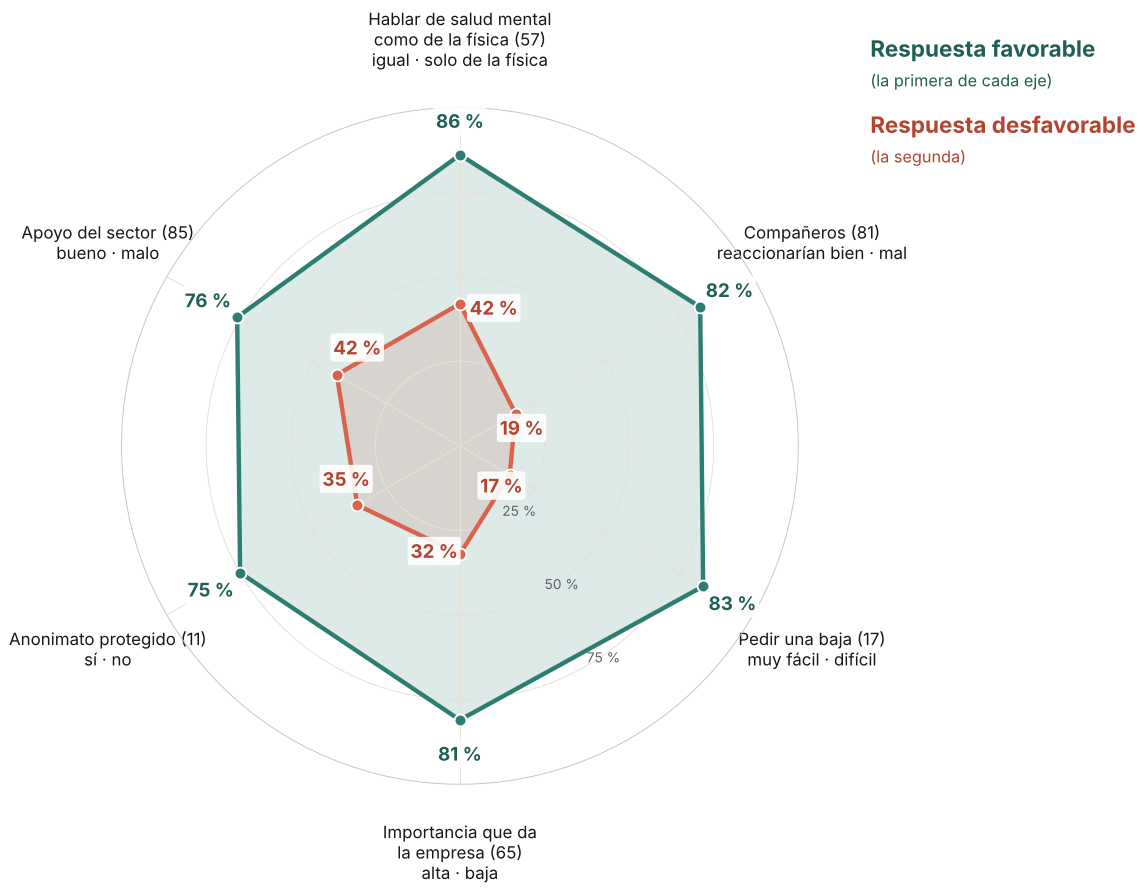

In [10]:
modelo19 = empleados[empleados[19].isin(["Sí", "No"])]                      # 875 personas: las del modelo 19
def hablaria(filtro):
    return (modelo19.loc[filtro, 19] == "Sí").mean() * 100                  # % que hablaría en ese grupo

num = lambda q: pd.to_numeric(modelo19[q], errors="coerce")
RADAR = [  # (etiqueta del eje, filtro favorable, filtro desfavorable)
    ("Hablar de salud mental\ncomo de la física (57)\nigual · solo de la física", modelo19[57] == "Igual de cómodo/a con ambas", modelo19[57] == "Salud física"),
    ("Compañeros (81)\nreaccionarían bien · mal", num(81) >= 7, num(81) <= 3),
    ("Pedir una baja (17)\nmuy fácil · difícil", modelo19[17] == "Muy fácil", modelo19[17] == "Difícil"),
    ("Importancia que da\nla empresa (65)\nalta · baja", num(65) >= 7, num(65) <= 3),
    ("Anonimato protegido (11)\nsí · no", modelo19[11] == "Sí", modelo19[11] == "No"),
    ("Apoyo del sector (85)\nbueno · malo", num(85) >= 4, num(85) <= 2)]
favorable = [round(hablaria(f)) for _, f, _ in RADAR]
desfavorable = [round(hablaria(d)) for _, _, d in RADAR]
display(pd.DataFrame({"favorable": favorable, "desfavorable": desfavorable},
                     index=[e.split("\n")[0] for e, _, _ in RADAR]))

etiquetas = [e for e, _, _ in RADAR]
angulos = np.linspace(0, 2 * np.pi, len(RADAR), endpoint=False).tolist(); angulos += angulos[:1]
fig = plt.figure(figsize=(12, 9.4)); ax = fig.add_axes([0.13, 0.08, 0.66, 0.8], polar=True)
for valores, color, tipo in [(desfavorable, CORAL, "d"), (favorable, VERDE, "f")]:
    v = valores + valores[:1]; ax.plot(angulos, v, color=color, lw=3.5); ax.fill(angulos, v, color=color, alpha=0.16)
    ax.scatter(angulos[:-1], valores, s=90, color=color, zorder=4, edgecolor="white", lw=1.5)
    for a, x in zip(angulos[:-1], valores):
        posicion = (a, x + 10) if tipo == "f" else (a + 0.24, x)
        ax.text(*posicion, f"{x} %", ha="center", va="center", fontsize=15, fontweight="bold",
                color=("#1F5F56" if tipo == "f" else "#B4432F"), bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.9), zorder=5)
ax.set_xticks(angulos[:-1]); ax.set_xticklabels(etiquetas, fontsize=13.5, color=TINTA)
ax.set_yticks([25, 50, 75]); ax.set_yticklabels(["25 %", "50 %", "75 %"], fontsize=11, color=TINTA2)
ax.set_ylim(0, 100); ax.spines["polar"].set_color(GRIS); ax.grid(color=GRIS2)
ax.set_theta_offset(np.pi / 2); ax.set_theta_direction(-1); ax.tick_params(axis="x", pad=44); ax.set_rlabel_position(150)
fig.text(0.84, 0.94, "Respuesta favorable", color="#1F5F56", fontsize=18, fontweight="bold"); fig.text(0.84, 0.905, "(la primera de cada eje)", color="#1F5F56", fontsize=13)
fig.text(0.84, 0.85, "Respuesta desfavorable", color="#B4432F", fontsize=18, fontweight="bold"); fig.text(0.84, 0.815, "(la segunda)", color="#B4432F", fontsize=13)
guardar(fig, "p_radar_clima.png")
plt.show()

**Lectura:** en las seis preguntas, quien da la respuesta favorable habla mucho más con su supervisor. Son cosas que la empresa puede cambiar: el clima con los compañeros, que pedir una baja sea fácil, la importancia que le da a la salud mental y que el anonimato sea creíble. Es una relación, no una causa.